In [7]:
import numpy as np
import matplotlib.pyplot as plt

In [9]:
%matplotlib inline

In [2]:
# 设定随机种子
np.random.seed(42)

In [3]:
# 真实参数
mu_x, mu_y = 3, 5
sigma_x, sigma_y = 2, 3
rho = 0.5

In [4]:
# 协方差矩阵
cov_matrix = [[sigma_x**2, rho * sigma_x * sigma_y],
              [rho * sigma_x * sigma_y, sigma_y**2]]

In [5]:
# 生成数据
data = np.random.multivariate_normal([mu_x, mu_y], cov_matrix, size=10)

In [6]:
data

array([[ 3.47790574,  6.54545019],
       [ 6.10792988,  5.85138154],
       [ 2.33807791,  4.47597649],
       [ 6.28019214,  9.0887754 ],
       [ 3.14914187,  3.25788412],
       [ 1.68655639,  3.96449637],
       [ 0.53999855,  7.01406946],
       [-0.18028084,  0.3454293 ],
       [ 2.07266495,  1.82664941],
       [-0.30259517,  3.31248305]])

In [10]:
# 初始化采样点
x_samples = [2.0]  # 随机选取初始值
y_samples = [5.0]

num_samples = 1000

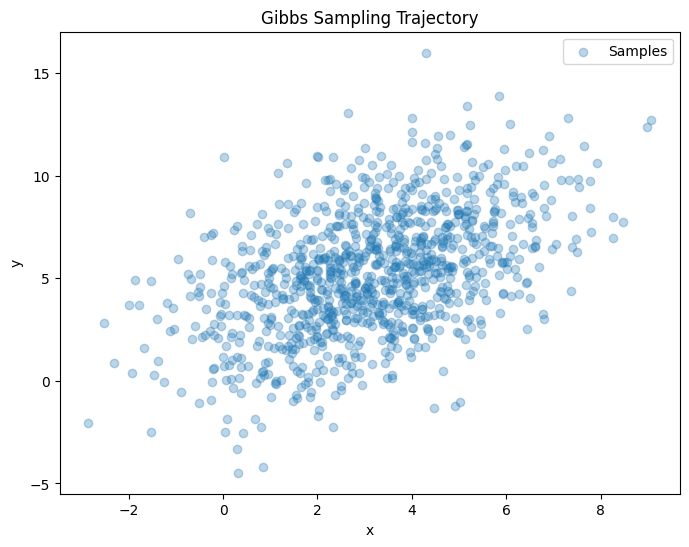

In [11]:
# 进行 Gibbs 采样
for i in range(num_samples):
    # 给定 y，采样 x
    y_prev = y_samples[-1]
    mu_x_given_y = mu_x + rho * (sigma_x / sigma_y) * (y_prev - mu_y)
    sigma_x_given_y = np.sqrt(sigma_x**2 * (1 - rho**2))
    x_new = np.random.normal(mu_x_given_y, sigma_x_given_y)

    # 给定 x，采样 y
    mu_y_given_x = mu_y + rho * (sigma_y / sigma_x) * (x_new - mu_x)
    sigma_y_given_x = np.sqrt(sigma_y**2 * (1 - rho**2))
    y_new = np.random.normal(mu_y_given_x, sigma_y_given_x)

    # 记录采样结果
    x_samples.append(x_new)
    y_samples.append(y_new)

# 转换为 NumPy 数组
x_samples = np.array(x_samples)
y_samples = np.array(y_samples)

# 画出 Gibbs 采样轨迹
plt.figure(figsize=(8, 6))
plt.scatter(x_samples, y_samples, alpha=0.3, label="Samples")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Gibbs Sampling Trajectory")
plt.legend()
plt.show()

In [12]:
mu_x_est = np.mean(x_samples)
mu_y_est = np.mean(y_samples)
sigma_x_est = np.std(x_samples)
sigma_y_est = np.std(y_samples)

print(f"估计的 μ_x: {mu_x_est:.2f}, 真实 μ_x: {mu_x}")
print(f"估计的 μ_y: {mu_y_est:.2f}, 真实 μ_y: {mu_y}")
print(f"估计的 σ_x: {sigma_x_est:.2f}, 真实 σ_x: {sigma_x}")
print(f"估计的 σ_y: {sigma_y_est:.2f}, 真实 σ_y: {sigma_y}")

估计的 μ_x: 3.13, 真实 μ_x: 3
估计的 μ_y: 5.24, 真实 μ_y: 5
估计的 σ_x: 1.93, 真实 σ_x: 2
估计的 σ_y: 2.99, 真实 σ_y: 3
